In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import display, Math

# Método de Newton-Raphson

Considere la función $f(x)=\cos{(x)} - x$, apróxime una raíz de f

Para poder utilizar Newton-Raphson se deben cumplir las siguientes condiciones:

1. $f \in C^2[a,b]$

Como $\cos{(x)}$ y $x$ son continuas en todo $\mathbb{R} $, la función es continua en todo $\mathbb{R}$, solo falta corroborar que es dos veces derivable


In [2]:
sp.init_printing()
x=sp.Symbol('x')
f=sp.cos(x) - x
df=sp.diff(f,x)
df_simplificada=sp.simplify(df)
display(Math(f"f'(x)={sp.latex(df_simplificada)}"))
ddf=sp.diff(df,x)
ddf_simplificada=sp.simplify(ddf)
display(Math(f"f''(x)={sp.latex(ddf_simplificada)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Con esto comprobamos que es dos veces derivable.

Ahora para encontrar una aproximación al punto donde está la raíz, debe cumplirse que 

$p \in [a,b] \quad \mid \quad f(p)=0$ y $f'(p) \neq 0$

Sea $f(p)=0$

$f'(p)=0 \leftrightarrow \{x \in \mathbb{R} \mid x=\frac{3 + 4k}{2}(\pi), \text{ con } k\in \mathbb{Z} \}$

En particular un intervalo para el que se cumplen las condiciones es $(-\frac{\pi}{2},\frac{3 \pi}{2})$

De esta forma obtenemos nuestra fórmula de Newton-Raphson

$P_n = P_{n-1}- \frac{\cos{(P_{n-1})}-x}{-\sin{(P_{n-1})}-1}$

Elaborando el código y eligiendo un $P_0=0.3$

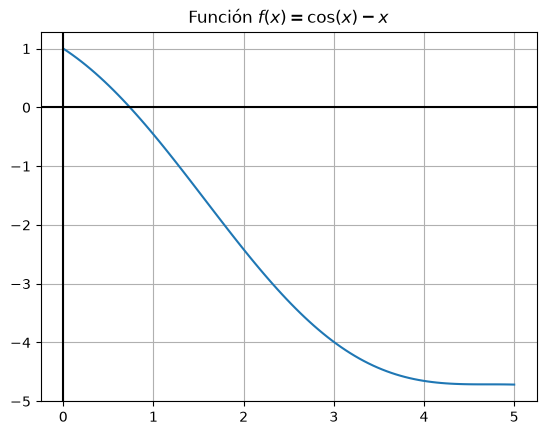

In [3]:
def f(x):
    return np.cos(x) - x
def df(x):
    return -np.sin(x) - 1
xx=np.linspace(0,5,100)
F1=f(xx)
plt.plot(xx,F1)
plt.title("Función $f(x) = \cos(x) - x$")
plt.grid(True)
plt.axhline(0,color="black")
plt.axvline(0,color="black")
plt.show()

In [18]:
def N(x):
    return x-(f(x)/df(x))
while True:
    try:
        tolerancia=float(input("Ingrese la tolerancia: "))
        break
    except:
        print("Ingrese un número real")
while True:
    try:
        iter=int(input("Ingrese el número de iteraciones: "))
        break
    except:
        print("Debe ser un número entero")
while True:
    try:
        p_0=float(input("Ingrese una aproximación inicial: "))
        break
    except:
        print("Ingrese un número real")
i=0
b=[p_0]
print(f"{'#':<8}{'P_n':<12}{'P_n+1':<12}{'Error':<12}")
while i<=iter:
    New=N(b[i])
    if np.abs(New-b[i]) <= tolerancia:
        print(f"{i:<8}{b[i]:<12.7f}{New:<12.7f}{np.abs(New - b[i]):<12.7f}")
        print(f"p={New}")
        pfinal=New
        break
    else:
        b.append(New)
        print(f"{i:<8}{b[i]:<12.7f}{New:<12.7f}{np.abs(New - b[i]):<12.7f}")
        i+=1

Ingrese la tolerancia:  .000000000000000001
Ingrese el número de iteraciones:  100
Ingrese una aproximación inicial:  0.3


#       P_n         P_n+1       Error       
0       0.3000000   0.8058481   0.5058481   
1       0.8058481   0.7400021   0.0658460   
2       0.7400021   0.7390853   0.0009168   
3       0.7390853   0.7390851   0.0000002   
4       0.7390851   0.7390851   0.0000000   
5       0.7390851   0.7390851   0.0000000   
p=0.7390851332151607


Comprobemos que en efecto es un punto cerca de la raíz evaluando en la función original

In [20]:
print(f"f({pfinal})={f(pfinal)}")

f(0.7390851332151607)=0.0
